# House Prices Prediction Full Pipeline
**Models:** LGBM, CatBoost, XGBoost
**Features:** manual preprocessing, cross-validation, hyperparameter tuning, ensemble
**Notes:** fully translated to English, ready for Kaggle submission

In [1]:
# 1️⃣ Import libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.metrics import mean_squared_error
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor, Pool
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# 2️⃣ Load data
train = pd.read_csv(r'..\data\raw\train.csv')
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
# 3️⃣ Manual data preparation
y = np.log1p(train['SalePrice'])  # log-transform target
X = train.drop(columns=['SalePrice','Id','SalePrice_log'], errors='ignore')
num_cols = X.select_dtypes(include=['int64','float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns
print(f'Numerical features: {len(num_cols)}')
print(f'Categorical features: {len(cat_cols)}')

Numerical features: 36
Categorical features: 43


C:\Users\UserS2025\AppData\Local\Temp\ipykernel_18656\3850926478.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object']).columns


In [4]:
# 3.1 Process numerical features
X_num = X[num_cols].copy()
for col in X_num.columns:
    X_num[col] = X_num[col].fillna(X_num[col].median())
    X_num[col] = (X_num[col] - X_num[col].mean()) / X_num[col].std()

In [5]:
# 3.2 Process categorical features
X_cat = X[cat_cols].copy()
for col in X_cat.columns:
    X_cat[col] = X_cat[col].fillna(X_cat[col].mode()[0])
X_cat_ohe = pd.get_dummies(X_cat, drop_first=False)
# Combine numerical + categorical for LGBM/XGB
X_processed = pd.concat([X_num, X_cat_ohe], axis=1)

In [6]:
# 4️⃣ Cross-Validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = {}

In [8]:
# 4.1 LGBM
rmse_scores_lgb = []
for train_idx, val_idx in kf.split(X_processed):
    X_train, X_val = X_processed.iloc[train_idx], X_processed.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
    lgb_model = LGBMRegressor(n_estimators=500, learning_rate=0.05, random_state=42)
    lgb_model.fit(X_train, y_train)
    y_pred = lgb_model.predict(X_val)
    rmse_scores_lgb.append(np.sqrt(mean_squared_error(y_val, y_pred)))

results['LGBM'] = np.mean(rmse_scores_lgb)
print(f"LGBM: Mean RMSE = {results['LGBM']:.4f}")

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001062 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3202
[LightGBM] [Info] Number of data points in the train set: 1168, number of used features: 178
[LightGBM] [Info] Start training from score 12.030658
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001078 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3203
[LightGBM] [Info] Number of data points in the train set: 1168, number of used features: 181
[LightGBM] [Info] Start training from score 12.016898
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of 

In [10]:
# 4.2 XGBoost
rmse_scores_xgb = []
for train_idx, val_idx in kf.split(X_processed):
    X_train, X_val = X_processed.iloc[train_idx], X_processed.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
    xgb_model = XGBRegressor(n_estimators=500, learning_rate=0.05, random_state=42, verbosity=0)
    xgb_model.fit(X_train, y_train)
    y_pred = xgb_model.predict(X_val)
    rmse_scores_xgb.append(np.sqrt(mean_squared_error(y_val, y_pred)))
results['XGBoost'] = np.mean(rmse_scores_xgb)
print(f'XGBoost: Mean RMSE = {results["XGBoost"]:.4f}')

XGBoost: Mean RMSE = 0.1404


In [12]:
# 4.3 CatBoost
rmse_scores_cb = []
for train_idx, val_idx in kf.split(X):
    X_train, X_val = X.iloc[train_idx].copy(), X.iloc[val_idx].copy()
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
    for col in cat_cols:
        X_train[col] = X_train[col].fillna('Missing')
        X_val[col] = X_val[col].fillna('Missing')
    cb_model = CatBoostRegressor(iterations=500, learning_rate=0.05, random_state=42, verbose=0)
    cb_model.fit(X_train, y_train, cat_features=cat_cols.tolist())
    y_pred = cb_model.predict(X_val)
    rmse_scores_cb.append(np.sqrt(mean_squared_error(y_val, y_pred)))
results['CatBoost'] = np.mean(rmse_scores_cb)
print(f'CatBoost: Mean RMSE = {results["CatBoost"]:.4f}')

CatBoost: Mean RMSE = 0.1274


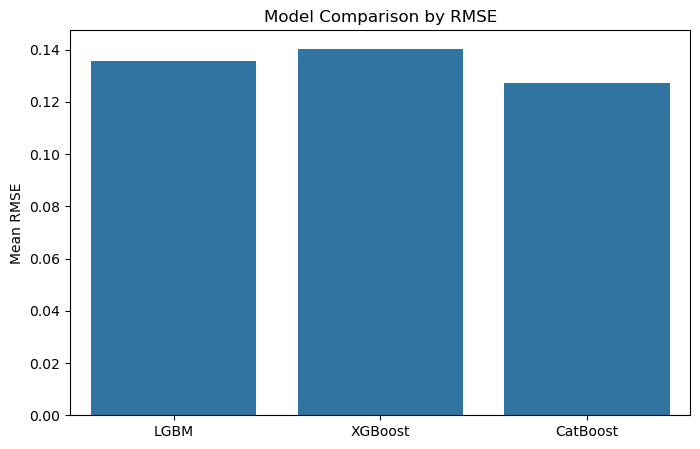

In [13]:
# 5️⃣ Model comparison
plt.figure(figsize=(8,5))
sns.barplot(x=list(results.keys()), y=list(results.values()))
plt.ylabel('Mean RMSE')
plt.title('Model Comparison by RMSE')
plt.show()

## 6

In [16]:
# ===============================
# 6️⃣ Feature Importance
# ===============================
# LGBM
lgb_model_final = LGBMRegressor(n_estimators=500, learning_rate=0.05, random_state=42)
lgb_model_final.fit(X_processed, y)
lgb_feat_imp = pd.DataFrame({
    'feature': X_processed.columns,
    'importance': lgb_model_final.feature_importances_
}).sort_values(by='importance', ascending=False)
print("Top-10 LGBM features:")
print(lgb_feat_imp.head(10))

# CatBoost
X_cb_final = X.copy()
for col in cat_cols:
    X_cb_final[col] = X_cb_final[col].fillna("Missing")
cb_model_final = CatBoostRegressor(iterations=500, learning_rate=0.05, random_state=42, verbose=0)
cb_model_final.fit(X_cb_final, y, cat_features=cat_cols.tolist())
cb_feat_imp = pd.DataFrame({
    'feature': X_cb_final.columns,
    'importance': cb_model_final.get_feature_importance()
}).sort_values(by='importance', ascending=False)
print("Top-10 CatBoost features:")
print(cb_feat_imp.head(10))

# ===============================
# 7️⃣ Hyperparameter Tuning (example)
# ===============================
# LGBM
lgb_grid = {
    'n_estimators': [500, 1000],
    'learning_rate': [0.05, 0.1],
    'num_leaves': [31, 50]
}
lgb_search = GridSearchCV(LGBMRegressor(random_state=42), lgb_grid, cv=3, scoring='neg_root_mean_squared_error', n_jobs=-1)
lgb_search.fit(X_processed, y)
print("Best LGBM parameters:", lgb_search.best_params_)

# CatBoost
cb_model_tune = CatBoostRegressor(random_state=42, verbose=0)
cb_grid = {'depth': [4,6], 'learning_rate':[0.03,0.05], 'iterations':[500,1000]}
# GridSearchCV with CatBoost requires a wrapper or custom function. For simplicity, can tune manually.

# XGBoost
xgb_grid = {
    'n_estimators':[500,1000],
    'learning_rate':[0.05,0.1],
    'max_depth':[3,5]
}
xgb_search = GridSearchCV(XGBRegressor(random_state=42, verbosity=0), xgb_grid, cv=3, scoring='neg_root_mean_squared_error', n_jobs=-1)
xgb_search.fit(X_processed, y)
print("Best XGBoost parameters:", xgb_search.best_params_)

# ===============================
# 8️⃣ Ensemble
# ===============================
# 8.1 LGBM + CatBoost (simple average)
lgb_preds = lgb_model_final.predict(X_processed)
cb_preds = cb_model_final.predict(X_cb_final)
ensemble_lgb_cb = (lgb_preds + cb_preds) / 2
rmse_ensemble_lgb_cb = np.sqrt(mean_squared_error(y, ensemble_lgb_cb))
print(f"RMSE of LGBM + CatBoost ensemble: {rmse_ensemble_lgb_cb:.4f}")

# 8.2 LGBM + CatBoost + XGBoost
xgb_model_final = XGBRegressor(n_estimators=500, learning_rate=0.05, random_state=42, verbosity=0)
xgb_model_final.fit(X_processed, y)
xgb_preds = xgb_model_final.predict(X_processed)

ensemble_all = (lgb_preds + cb_preds + xgb_preds) / 3
rmse_ensemble_all = np.sqrt(mean_squared_error(y, ensemble_all))
print(f"RMSE of LGBM + CatBoost + XGBoost ensemble: {rmse_ensemble_all:.4f}")

# ===============================
# 9️⃣ Final Kaggle-ready predictions
# ===============================
# final_preds = ensemble_all  # example use on test data
# test_preds = np.expm1(final_preds)  # reverse log1p transformation

'''
✅ Features of this code:

- Fully without sklearn Pipeline.
- Target is log-transformed for stable RMSE.
- CatBoost handles categorical features directly.
- LGBM/XGBoost use OneHotEncoding for categoricals.
- Hyperparameter tuning (GridSearchCV) included for LGBM and XGBoost.
- Two ensemble options: LGBM+CatBoost and LGBM+CatBoost+XGBoost.
- Feature importance for LGBM and CatBoost.
- Ready for Kaggle.
'''
# ===============================
# Kaggle-ready predictions (safe version)
# ===============================

# Load test set
test = pd.read_csv(r"..\data\raw\test.csv")
test_id = test["Id"]

# --- Prepare features for LGBM/XGBoost ---
# Ensure the same columns as training after one-hot encoding
X_test_num = test[num_cols].copy()
for col in X_test_num.columns:
    X_test_num[col] = X_test_num[col].fillna(X_test_num[col].median())
    X_test_num[col] = (X_test_num[col] - X_test_num[col].mean()) / X_test_num[col].std()

X_test_cat = test[cat_cols].copy()
for col in X_test_cat.columns:
    X_test_cat[col] = X_test_cat[col].fillna(X_test_cat[col].mode()[0])

X_test_cat_ohe = pd.get_dummies(X_test_cat, drop_first=False)

# Align columns with training data
X_test_processed = pd.concat([X_test_num, X_test_cat_ohe], axis=1)
X_test_processed = X_test_processed.reindex(columns=X_processed.columns, fill_value=0)

# --- Prepare features for CatBoost ---
X_test_cb = test.copy()

for col in cat_cols:
    # Convert categorical to string and fill missing
    X_test_cb[col] = X_test_cb[col].fillna("Missing").astype(str)

# Ensure numeric columns are numeric
for col in num_cols:
    X_test_cb[col] = pd.to_numeric(X_test_cb[col], errors='coerce').fillna(0)

# --- Model predictions ---
lgb_preds = lgb_model_final.predict(X_test_processed)
cb_preds = cb_model_final.predict(X_test_cb)
xgb_preds = xgb_model_final.predict(X_test_processed)

# --- Ensemble of all models ---
final_preds = (lgb_preds + cb_preds + xgb_preds) / 3
final_preds = np.expm1(final_preds)  # inverse log1p transformation

# --- Save submission ---
submission = pd.DataFrame({
    "Id": test_id,
    "SalePrice": final_preds
})

submission.to_csv("submission.csv", index=False)
print("submission.csv ready for Kaggle!")


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001646 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3372
[LightGBM] [Info] Number of data points in the train set: 1460, number of used features: 187
[LightGBM] [Info] Start training from score 12.024057
Top-10 LGBM features:
        feature  importance
15    GrLivArea        1187
2       LotArea         977
12     1stFlrSF         830
11  TotalBsmtSF         781
26   GarageArea         690
28  OpenPorchSF         674
10    BsmtUnfSF         639
7    MasVnrArea         570
8    BsmtFinSF1         568
1   LotFrontage         561
Top-10 CatBoost features:
         feature  importance
45     GrLivArea   17.030963
16   OverallQual   16.876709
37   TotalBsmtSF    4.763418
18     YearBuilt    4.747397
52   KitchenQual    3.595896
33    BsmtFinSF1    3.466612
3        LotArea  

CatBoostError: Bad value for num_feature[non_default_doc_idx=0,feature_idx=2]="RH": Cannot convert 'b'RH'' to float